# M0: EDA of Kang 2018 (IFN-β vs control PBMCs)

Contract: `audit/contracts/M0_eda.md`. Logic lives in `src/m0_qc.py` (tested); this notebook shows the data.
Nothing is dropped here except the agreed basic filters (cells ≥ 200 genes, genes ≥ 3 cells). Everything else is **flagged** for the user.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", message=".*OldFormatWarning.*")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np


def neutral_lines(parts):
    for k in ("cmins", "cmaxes", "cbars", "cmedians"):
        if k in parts:
            parts[k].set_color("#5c5c57"); parts[k].set_linewidth(1)
import pandas as pd
from IPython.display import display

from src import m0_qc

pd.set_option("display.width", 160, "display.max_columns", 20)

# Input files, fingerprints and cell-type names are defined once, in src/m0_qc.py
H5AD, GEO = m0_qc.KANG_H5AD, m0_qc.KANG_GEO
H5AD_SHA, GEO_SHA = m0_qc.KANG_H5AD_SHA256, m0_qc.KANG_GEO_SHA256
CELL_TYPES = m0_qc.KANG_CELL_TYPES
# Thresholds (all agreed; passed explicitly everywhere, and drawn on the plots from these values)
MIN_GENES, MIN_CELLS, N_MADS, MIN_CELLS_GROUP, MIN_PAIRED_DONORS = 200, 3, 5.0, 10, 3
KEY_GENES = ["ISG15", "IFI6", "IFIT1", "IFIT2", "IFIT3", "MX1", "OAS1", "OAS2", "OAS3", "RSAD2", "IRF7", "STAT1"]

# Kang 2018 Fig 3 colours, donor order and stacking order: defined once, in src/figures.py
from src.figures import CT_COLORS, COND_COLORS, DONOR_ORDER, STACK_ORDER
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8a85", "text.color": "#2b2b28", "axes.labelcolor": "#2b2b28",
                     "xtick.color": "#5c5c57", "ytick.color": "#5c5c57", "figure.dpi": 110})

## 1. The raw inputs: what's in each table

In [2]:
raw, geo = m0_qc.load_inputs(H5AD, GEO, expected_sha256=H5AD_SHA, expected_geo_sha256=GEO_SHA)
print(raw)
print("\nh5ad obs: head"); display(raw.obs.head())
print("h5ad obs: tail"); display(raw.obs.tail())
print("h5ad var: head / tail"); display(raw.var.head()); display(raw.var.tail())
print("GEO metadata: head"); display(geo.head())
print("GEO metadata: tail"); display(geo.tail())

AnnData object with n_obs × n_vars = 24673 × 15706
    obs: 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters'
    var: 'name'
    obsm: 'X_pca', 'X_umap'

h5ad obs: head


,nCount_RNA,nFeature_RNA,tsne1,tsne2,label,cluster,cell_type,replicate,nCount_SCT,nFeature_SCT,integrated_snn_res.0.4,seurat_clusters
index,,,,,,,,,,,,
AAACATACATTTCC-1,3017.0,877,-27.640373,14.966629,ctrl,9,CD14+ Monocytes,patient_1016,1704.0,711,1,1
AAACATACCAGAAA-1,2481.0,713,-27.493646,28.924885,ctrl,9,CD14+ Monocytes,patient_1256,1614.0,662,1,1
AAACATACCATGCA-1,703.0,337,-10.468194,-5.984389,ctrl,3,CD4 T cells,patient_1488,908.0,337,6,6
AAACATACCTCGCT-1,3420.0,850,-24.367997,20.429285,ctrl,9,CD14+ Monocytes,patient_1256,1738.0,653,1,1
AAACATACCTGGTA-1,3158.0,1111,27.952170,24.159738,ctrl,4,Dendritic cells,patient_1039,1857.0,928,12,12


h5ad obs: tail


,nCount_RNA,nFeature_RNA,tsne1,tsne2,label,cluster,cell_type,replicate,nCount_SCT,nFeature_SCT,integrated_snn_res.0.4,seurat_clusters
index,,,,,,,,,,,,
TTTGCATGCCTGAA-2,1033.0,468,18.268321,1.058202,stim,6,CD4 T cells,patient_1244,1128.0,468,2,2
TTTGCATGCCTGTC-2,2116.0,819,-11.563067,2.574095,stim,4,B cells,patient_1256,1669.0,799,3,3
TTTGCATGCTAAGC-2,1522.0,523,25.142392,6.603815,stim,6,CD4 T cells,patient_107,1422.0,523,0,0
TTTGCATGGGACGA-2,1143.0,503,14.359657,10.965601,stim,6,CD4 T cells,patient_1488,1185.0,503,0,0
TTTGCATGTCTTAC-2,1031.0,421,14.572118,-4.713942,stim,5,CD4 T cells,patient_1016,1144.0,419,2,2


h5ad var: head / tail


...

,name
index,
C21orf58,C21orf58
PCNT,PCNT
DIP2A,DIP2A
S100B,S100B
PRMT2,PRMT2


GEO metadata: head


,tsne1,tsne2,ind,stim,cluster,cell,multiplets
AAACATACAATGCC-1,-4.277833,-19.294709,107,ctrl,5,CD4 T cells,doublet
AAACATACATTTCC-1,-27.640373,14.966629,1016,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGAAA-1,-27.493646,28.924885,1256,ctrl,9,CD14+ Monocytes,singlet
AAACATACCAGCTA-1,-28.132584,24.925484,1256,ctrl,9,CD14+ Monocytes,doublet
AAACATACCATGCA-1,-10.468194,-5.984389,1488,ctrl,3,CD4 T cells,singlet


GEO metadata: tail


,tsne1,tsne2,ind,stim,cluster,cell,multiplets
TTTGCATGCTAAGC-1,25.142392,6.603815,107,stim,6,CD4 T cells,singlet
TTTGCATGGGACGA-1,14.359657,10.965601,1488,stim,6,CD4 T cells,singlet
TTTGCATGGTGAGG-1,27.317997,7.933458,1488,stim,6,CD4 T cells,ambs
TTTGCATGGTTTGG-1,13.744084,9.347784,1244,stim,6,CD4 T cells,ambs
TTTGCATGTCTTAC-1,14.572118,-4.713942,1016,stim,5,CD4 T cells,singlet


In [3]:
def column_summary(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_NA": df.isna().sum(),
        "n_unique": df.nunique(),
        "example": df.iloc[0].astype(str),
    })

print("h5ad obs columns"); display(column_summary(raw.obs))
print("GEO columns"); display(column_summary(geo))

counts = pd.Series({
    "h5ad cells": raw.n_obs, "h5ad unique barcodes": raw.obs_names.nunique(),
    "h5ad genes": raw.n_vars, "h5ad duplicated gene names": int(raw.var_names.duplicated().sum()),
    "GEO rows (droplets)": len(geo), "GEO unique barcodes": geo.index.nunique(),
    "donors (h5ad replicate)": raw.obs["replicate"].nunique(),
})
display(counts.to_frame("value"))

h5ad obs columns


,dtype,n_NA,n_unique,example
nCount_RNA,float64,0,3667,3017.0
nFeature_RNA,int32,0,1251,877
tsne1,float64,0,24673,-27.6403728343912
tsne2,float64,0,24673,14.9666293340935
label,category,0,2,ctrl
cluster,int32,0,10,9
cell_type,category,0,8,CD14+ Monocytes
replicate,category,0,8,patient_1016
nCount_SCT,float64,0,1302,1704.0
nFeature_SCT,int32,0,965,711


GEO columns


,dtype,n_NA,n_unique,example
tsne1,float64,0,29065,-4.27783307986973
tsne2,float64,0,29065,-19.2947087769253
ind,int64,0,8,107
stim,object,0,2,ctrl
cluster,int64,0,10,5
cell,object,9,8,CD4 T cells
multiplets,object,0,3,doublet


,value
h5ad cells,24673
h5ad unique barcodes,24673
h5ad genes,15706
h5ad duplicated gene names,0
GEO rows (droplets),29065
GEO unique barcodes,29065
donors (h5ad replicate),8


### Every metadata column, with a plot suited to it
Categorical → bar of counts; numeric → histogram. Columns from the later re-analysis (`nCount_SCT`, `seurat_clusters`, …) are shown but **not used**.

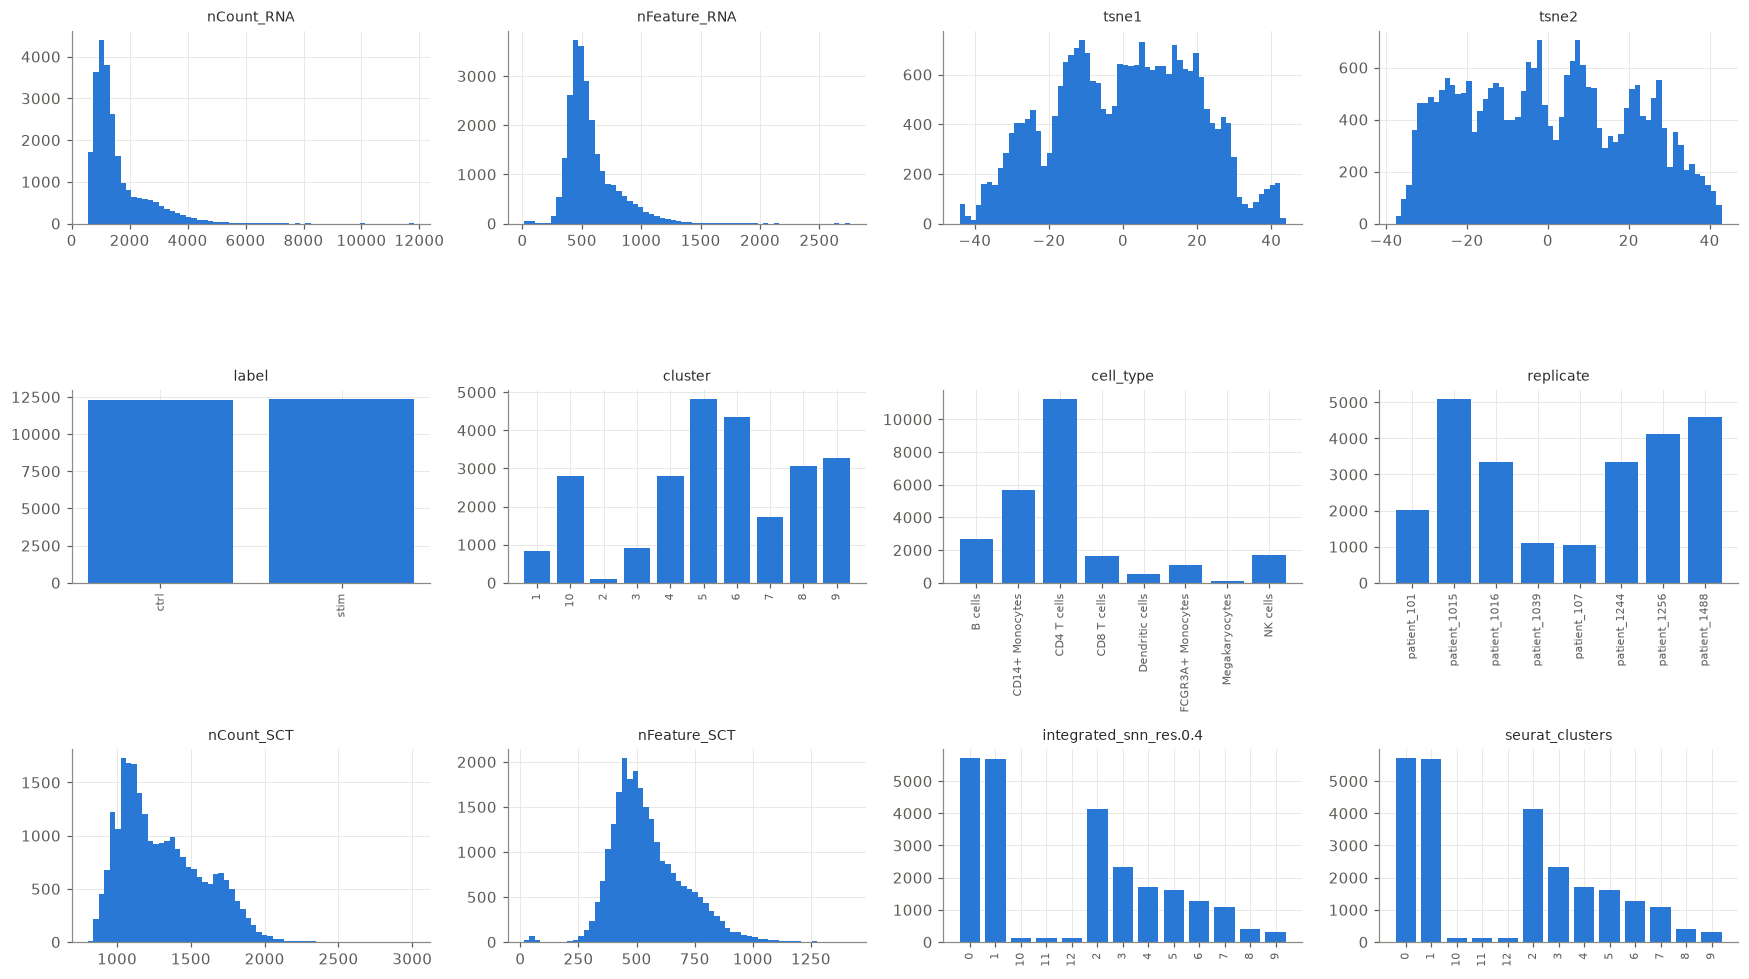

In [4]:
cols = list(raw.obs.columns)
fig, axes = plt.subplots(int(np.ceil(len(cols) / 4)), 4, figsize=(16, 3 * int(np.ceil(len(cols) / 4))))
for ax, c in zip(axes.ravel(), cols):
    s = raw.obs[c]
    if s.dtype.name in ("category", "object") or s.nunique() <= 15:
        vc = s.astype(str).value_counts().sort_index()
        ax.bar(range(len(vc)), vc.values, color="#2a78d6", width=0.8)
        ax.set_xticks(range(len(vc)), vc.index, rotation=90, fontsize=7)
    else:
        ax.hist(s, bins=60, color="#2a78d6")
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
fig.tight_layout()

Same for every column of the authors' GEO table (all 29,065 droplets, including doublets). Most duplicate h5ad columns and are checked cell by cell in the join (§3).

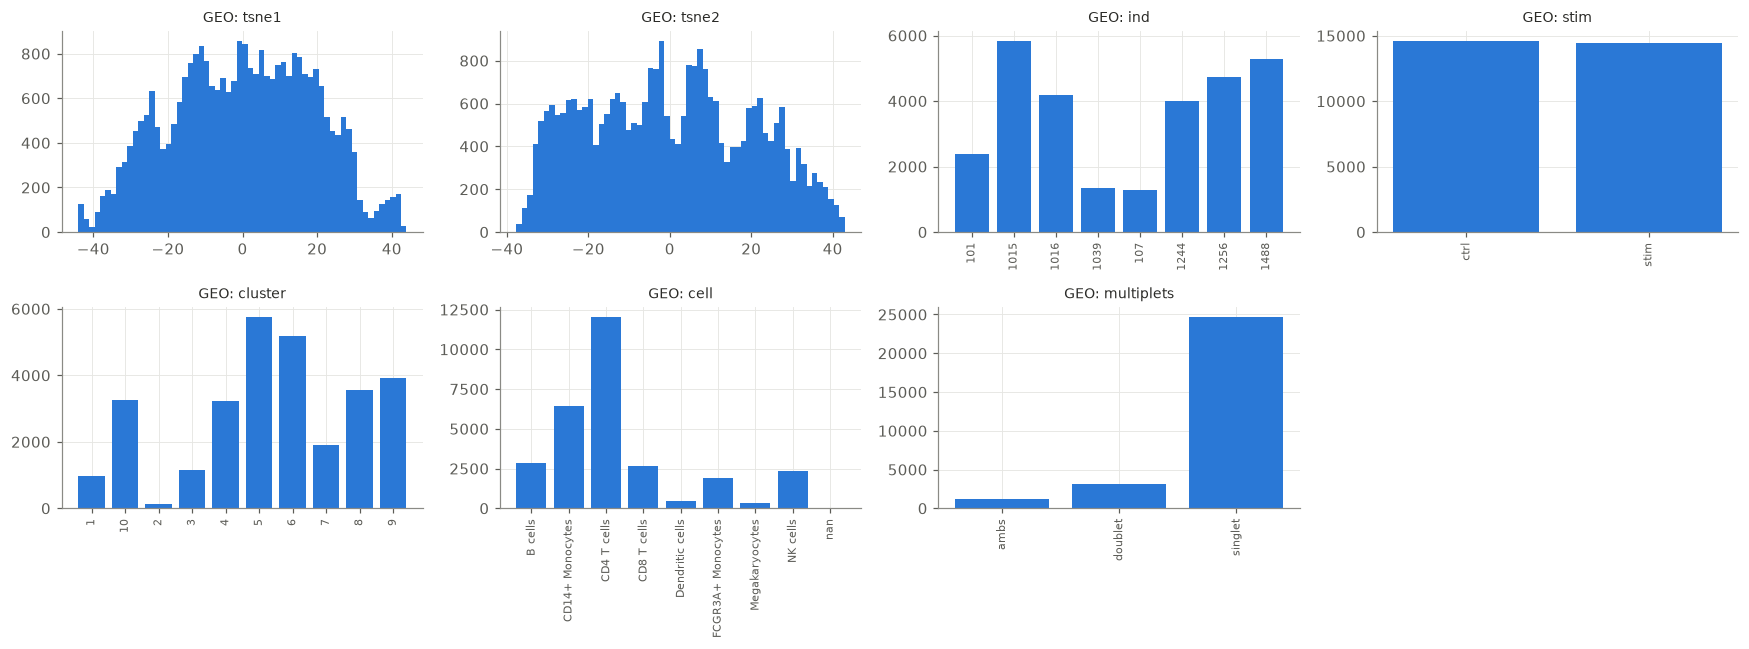

In [5]:
gcols = list(geo.columns)
fig, axes = plt.subplots(int(np.ceil(len(gcols) / 4)), 4, figsize=(16, 3 * int(np.ceil(len(gcols) / 4))))
for ax, c in zip(axes.ravel(), gcols):
    s = geo[c]
    if s.dtype.name in ("category", "object") or s.nunique() <= 15:
        vc = s.astype(str).value_counts().sort_index()
        ax.bar(range(len(vc)), vc.values, color="#2a78d6", width=0.8)
        ax.set_xticks(range(len(vc)), vc.index, rotation=90, fontsize=7)
    else:
        ax.hist(s, bins=60, color="#2a78d6")
    ax.set_title(f"GEO: {c}", fontsize=9)
for ax in axes.ravel()[len(gcols):]:
    ax.axis("off")
fig.tight_layout()

## 2. The counts matrix

In [6]:
v = raw.X.data
print("X type:", type(raw.X).__name__, raw.X.dtype, "| non-negative integers:", bool((v >= 0).all() and np.array_equal(v, np.round(v))))
print("Max count:", v.max(), "| fraction of zero entries: %.3f" % (1 - raw.X.nnz / np.prod(raw.shape)))
print("MT- genes:", int(raw.var_names.str.startswith("MT-").sum()), "| RPS/RPL-prefix genes:", int(raw.var_names.str.match(r"^RP[SL]").sum()),
      "| counted as ribosomal (minus 14 non-ribosomal, D4):", int(m0_qc.ribosomal_mask(raw.var_names).sum()))
display(pd.DataFrame({"present": [g in raw.var_names for g in KEY_GENES]}, index=KEY_GENES).T)

X type: csc_matrix float32 | non-negative integers: True
Max count: 3828.0 | fraction of zero entries: 0.963
MT- genes: 0 | RPS/RPL-prefix genes: 98 | counted as ribosomal (minus 14 non-ribosomal, D4): 84


,ISG15,IFI6,IFIT1,IFIT2,IFIT3,MX1,OAS1,OAS2,OAS3,RSAD2,IRF7,STAT1
present,True,True,True,True,True,True,True,True,True,True,True,True


## 3. Join the authors' labels (key = barcode sequence + condition)
234 barcode sequences appear in both conditions among these singlets; a raw-barcode join would silently label only the control cells.

In [7]:
joined = m0_qc.join_author_metadata(raw, geo)
core = raw.obs_names.str.replace(r"-\d+$", "", regex=True)
n_both = int((pd.Series(raw.obs["label"].astype(str).values, index=core).groupby(level=0).nunique() == 2).sum())
print(f"matched {joined.n_obs} of {raw.n_obs} cells | sequences in both conditions: {n_both}")
print("control / treatment:", m0_qc.infer_conditions(joined.obs["condition"]))
agree = (raw.obs["cell_type"].astype(str).values == joined.obs["cell_type"].values).mean()
print(f"re-analysis labels agree with the authors' on {agree:.1%} of cells")
display(pd.crosstab(joined.obs["cell_type"], raw.obs["cell_type"].values, rownames=["authors"], colnames=["re-analysis"], margins=True))
display(joined.obs.head()); display(joined.obs.tail())

matched 24673 of 24673 cells | sequences in both conditions: 234
control / treatment: ('ctrl', 'stim')
re-analysis labels agree with the authors' on 91.0% of cells


re-analysis,CD4 T cells,CD14+ Monocytes,B cells,NK cells,CD8 T cells,FCGR3A+ Monocytes,Dendritic cells,Megakaryocytes,All
authors,,,,,,,,,
B cells,37,0,2520,2,0,0,10,4,2573
CD14+ Monocytes,9,5216,5,0,0,27,97,31,5385
CD4 T cells,10310,1,32,4,10,0,0,32,10389
CD8 T cells,673,0,3,79,1283,0,1,3,2042
Dendritic cells,12,6,36,0,0,0,378,0,432
FCGR3A+ Monocytes,21,441,25,1,1,1060,42,8,1599
Megakaryocytes,139,28,30,1,7,2,1,52,260
NK cells,37,5,0,1629,320,0,0,2,1993
All,11238,5697,2651,1716,1621,1089,529,132,24673


,barcode,condition,donor,cell_type,cluster,tsne1,tsne2
index,,,,,,,
AAACATACATTTCC-1,AAACATACATTTCC-1,ctrl,patient_1016,CD14+ Monocytes,9,-27.640373,14.966629
AAACATACCAGAAA-1,AAACATACCAGAAA-1,ctrl,patient_1256,CD14+ Monocytes,9,-27.493646,28.924885
AAACATACCATGCA-1,AAACATACCATGCA-1,ctrl,patient_1488,CD4 T cells,3,-10.468194,-5.984389
AAACATACCTCGCT-1,AAACATACCTCGCT-1,ctrl,patient_1256,CD14+ Monocytes,9,-24.367997,20.429285
AAACATACCTGGTA-1,AAACATACCTGGTA-1,ctrl,patient_1039,Dendritic cells,4,27.952170,24.159738


,barcode,condition,donor,cell_type,cluster,tsne1,tsne2
index,,,,,,,
TTTGCATGCCTGAA-2,TTTGCATGCCTGAA-2,stim,patient_1244,CD4 T cells,6,18.268321,1.058202
TTTGCATGCCTGTC-2,TTTGCATGCCTGTC-2,stim,patient_1256,B cells,4,-11.563067,2.574095
TTTGCATGCTAAGC-2,TTTGCATGCTAAGC-2,stim,patient_107,CD4 T cells,6,25.142392,6.603815
TTTGCATGGGACGA-2,TTTGCATGGGACGA-2,stim,patient_1488,CD4 T cells,6,14.359657,10.965601
TTTGCATGTCTTAC-2,TTTGCATGTCTTAC-2,stim,patient_1016,CD4 T cells,5,14.572118,-4.713942


## 4. QC metrics and the agreed basic filters
Cutoffs are drawn on the plots: cells need ≥ 200 genes; genes need ≥ 3 cells.

cells 24673 → 24562 (removed 111); genes 15706 → 15701 (removed 5)


lowest genes-per-cell values: [12 18 22 22 24 29 30 31 33 34]


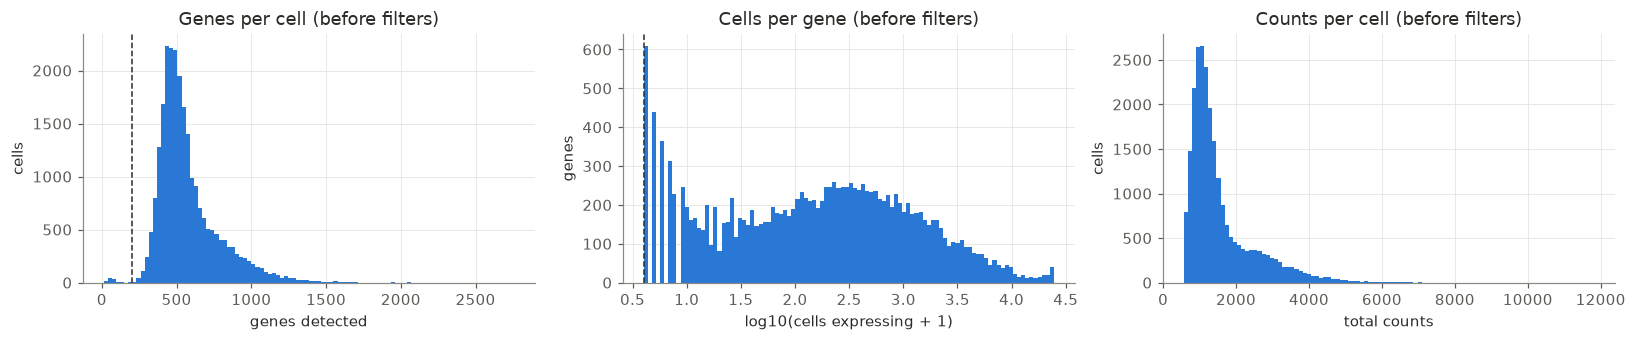

In [8]:
qc = m0_qc.compute_qc_metrics(joined)
filtered = m0_qc.basic_filter(qc, min_genes=MIN_GENES, min_cells=MIN_CELLS)
print(f"cells {qc.n_obs} → {filtered.n_obs} (removed {qc.n_obs - filtered.n_obs}); genes {qc.n_vars} → {filtered.n_vars} (removed {qc.n_vars - filtered.n_vars})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].hist(qc.obs["n_genes"], bins=100, color="#2a78d6"); axes[0].axvline(MIN_GENES, color="#2b2b28", lw=1, ls="--")
axes[0].set(title="Genes per cell (before filters)", xlabel="genes detected", ylabel="cells")
axes[1].hist(np.log10(qc.var["n_cells"] + 1), bins=100, color="#2a78d6"); axes[1].axvline(np.log10(MIN_CELLS + 1), color="#2b2b28", lw=1, ls="--")
axes[1].set(title="Cells per gene (before filters)", xlabel="log10(cells expressing + 1)", ylabel="genes")
axes[2].hist(qc.obs["n_counts"], bins=100, color="#2a78d6")
axes[2].set(title="Counts per cell (before filters)", xlabel="total counts", ylabel="cells")
fig.tight_layout()
print("lowest genes-per-cell values:", np.sort(qc.obs["n_genes"].values)[:10])

## 5. Run the tested pipeline and write the outputs
`run_m0_kang` repeats the steps above end to end on the real files (fingerprints and cell-type names always checked), validates everything **before** writing, and logs cells in → out.

In [9]:
flow = m0_qc.run_m0_kang(ROOT / "data/processed", audit_dir=ROOT / "audit", min_genes=MIN_GENES, min_cells=MIN_CELLS,
                         n_mads=N_MADS, min_cells_group=MIN_CELLS_GROUP, min_paired_donors=MIN_PAIRED_DONORS)
display(pd.DataFrame(flow))
m0 = ad.read_h5ad(ROOT / "data/processed/m0_cells.h5ad")
obs = m0.obs
assert m0.n_obs == filtered.n_obs and m0.n_vars == filtered.n_vars, "notebook filtering and run_m0 disagree"
print(m0)
print("uns:", {k: m0.uns[k] for k in ("control", "treatment")})
display(obs.head()); display(obs.tail())
display(m0.var.head()); display(m0.var.tail())

,step,n_cells_in,n_cells_out,n_genes_in,n_genes_out,n_matched
0,load,24673,24673,15706,15706,NaN
1,join,24673,24673,15706,15706,24673.0
2,qc_metrics,24673,24673,15706,15706,NaN
3,basic_filter,24673,24562,15706,15701,NaN
4,flag_qc,24562,24562,15701,15701,NaN


AnnData object with n_obs × n_vars = 24562 × 15701
    obs: 'barcode', 'condition', 'donor', 'cell_type', 'cluster', 'tsne1', 'tsne2', 'n_counts', 'n_genes', 'pct_ribo', 'flag_outlier', 'flag_small_group', 'flag_underpowered_celltype'
    var: 'name', 'n_cells'
    uns: 'control', 'treatment'
    obsm: 'X_pca', 'X_umap'
uns: {'control': 'ctrl', 'treatment': 'stim'}


,barcode,condition,donor,cell_type,cluster,tsne1,tsne2,n_counts,n_genes,pct_ribo,flag_outlier,flag_small_group,flag_underpowered_celltype
index,,,,,,,,,,,,,
AAACATACATTTCC-1,AAACATACATTTCC-1,ctrl,patient_1016,CD14+ Monocytes,9,-27.640373,14.966629,3017.0,877,15.180643,False,False,False
AAACATACCAGAAA-1,AAACATACCAGAAA-1,ctrl,patient_1256,CD14+ Monocytes,9,-27.493646,28.924885,2481.0,713,4.796453,False,False,False
AAACATACCATGCA-1,AAACATACCATGCA-1,ctrl,patient_1488,CD4 T cells,3,-10.468194,-5.984389,703.0,337,9.103841,False,False,False
AAACATACCTCGCT-1,AAACATACCTCGCT-1,ctrl,patient_1256,CD14+ Monocytes,9,-24.367997,20.429285,3420.0,850,9.970760,False,False,False
AAACATACCTGGTA-1,AAACATACCTGGTA-1,ctrl,patient_1039,Dendritic cells,4,27.952170,24.159738,3158.0,1111,18.366055,False,True,False


,barcode,condition,donor,cell_type,cluster,tsne1,tsne2,n_counts,n_genes,pct_ribo,flag_outlier,flag_small_group,flag_underpowered_celltype
index,,,,,,,,,,,,,
TTTGCATGCCTGAA-2,TTTGCATGCCTGAA-2,stim,patient_1244,CD4 T cells,6,18.268321,1.058202,1033.0,468,27.976767,False,False,False
TTTGCATGCCTGTC-2,TTTGCATGCCTGTC-2,stim,patient_1256,B cells,4,-11.563067,2.574095,2116.0,819,29.442345,False,False,False
TTTGCATGCTAAGC-2,TTTGCATGCTAAGC-2,stim,patient_107,CD4 T cells,6,25.142392,6.603815,1522.0,523,42.904072,False,False,False
TTTGCATGGGACGA-2,TTTGCATGGGACGA-2,stim,patient_1488,CD4 T cells,6,14.359657,10.965601,1143.0,503,32.895889,False,False,False
TTTGCATGTCTTAC-2,TTTGCATGTCTTAC-2,stim,patient_1016,CD4 T cells,5,14.572118,-4.713942,1031.0,421,33.947624,False,False,False


,name,n_cells
index,,
AL627309.1,AL627309.1,6
RP11-206L10.2,RP11-206L10.2,6
RP11-206L10.9,RP11-206L10.9,7
FAM87B,FAM87B,4
LINC00115,LINC00115,90


,name,n_cells
index,,
C21orf58,C21orf58,31
PCNT,PCNT,130
DIP2A,DIP2A,360
S100B,S100B,179
PRMT2,PRMT2,4449


## 6. Cells per donor, and genes detected per donor

condition,ctrl,stim,total
donor,,,
patient_1039,408,584,992
patient_107,517,525,1042
patient_101,858,1166,2024
patient_1016,1723,1635,3358
patient_1244,1879,1464,3343
patient_1256,2108,2026,4134
patient_1488,2030,2549,4579
patient_1015,2738,2352,5090


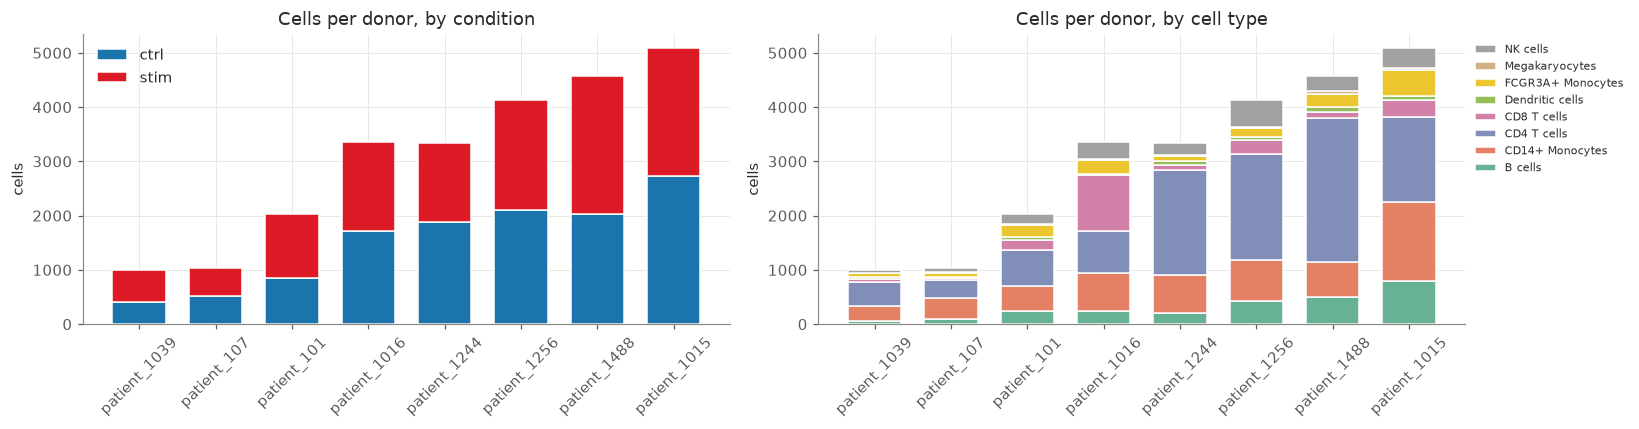

In [10]:
donors = [d for d in DONOR_ORDER if d in set(obs["donor"])]  # paper order (Kang Fig 3d)
assert len(donors) == obs["donor"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
by_cond = pd.crosstab(obs["donor"], obs["condition"]).loc[donors]
bottom = np.zeros(len(donors))
for c in ["ctrl", "stim"]:
    axes[0].bar(donors, by_cond[c], bottom=bottom, color=COND_COLORS[c], label=c, width=0.7, edgecolor="white", linewidth=1)
    bottom += by_cond[c].values
axes[0].set(title="Cells per donor, by condition", ylabel="cells"); axes[0].legend(frameon=False)
by_ct = pd.crosstab(obs["donor"], obs["cell_type"]).loc[donors, STACK_ORDER]
bottom = np.zeros(len(donors))
for ct in STACK_ORDER:
    axes[1].bar(donors, by_ct[ct], bottom=bottom, color=CT_COLORS[ct], label=ct, width=0.7, edgecolor="white", linewidth=1)
    bottom += by_ct[ct].values
axes[1].set(title="Cells per donor, by cell type", ylabel="cells")
h, l = axes[1].get_legend_handles_labels(); axes[1].legend(h[::-1], l[::-1], frameon=False, fontsize=7, bbox_to_anchor=(1, 1))
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
display(by_cond.assign(total=by_cond.sum(1)))

condition,ctrl,stim
donor,,
patient_101,534.0,546.0
patient_107,542.0,541.0
patient_1015,528.0,551.0
patient_1016,469.0,491.0
patient_1039,564.0,567.0
patient_1244,512.0,550.0
patient_1256,517.0,534.0
patient_1488,478.0,512.0


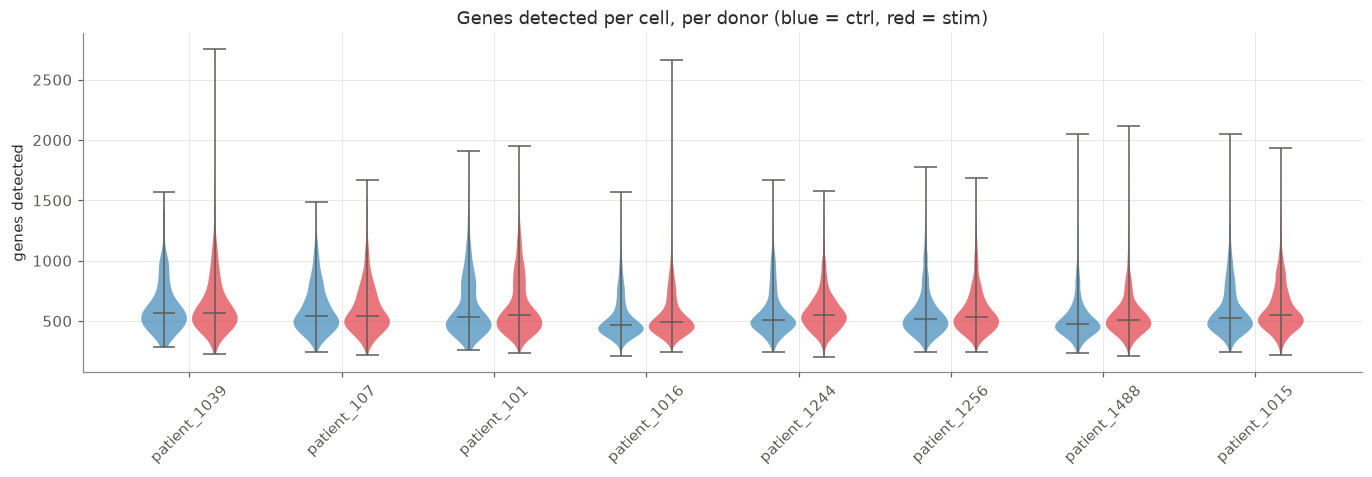

In [11]:
fig, ax = plt.subplots(figsize=(15, 4))
pos, data, colors = [], [], []
for i, d in enumerate(donors):
    for j, c in enumerate(["ctrl", "stim"]):
        pos.append(i * 3 + j); data.append(obs.loc[(obs.donor == d) & (obs.condition == c), "n_genes"].values); colors.append(COND_COLORS[c])
parts = ax.violinplot(data, positions=pos, showmedians=True, widths=0.9)
neutral_lines(parts)
for body, col in zip(parts["bodies"], colors):
    body.set_facecolor(col); body.set_alpha(0.6)
ax.set_xticks([i * 3 + 0.5 for i in range(len(donors))], donors, rotation=45)
ax.set(title="Genes detected per cell, per donor (blue = ctrl, red = stim)", ylabel="genes detected")
display(obs.groupby(["donor", "condition"], observed=True)["n_genes"].median().unstack().round(0))

## 7. Per-cell QC distributions, with outliers flagged (> 5 raw MADs above or below, within donor × condition × cell type; groups < 10 cells not assessed)

,n_counts,n_genes,pct_ribo
condition,,,
ctrl,1201.0,508.0,25.700001
stim,1284.0,531.0,22.299999


condition,outliers_ctrl,outliers_stim
donor,,
patient_101,16,24
patient_107,7,10
patient_1015,65,49
patient_1016,38,37
patient_1039,8,11
patient_1244,45,18
patient_1256,44,32
patient_1488,48,62


flagged 514: 379 above their group's median counts, 135 at or below


,flagged,cells,pct
cell_type,,,
B cells,85,2571,3.3
CD14+ Monocytes,14,5355,0.3
CD4 T cells,172,10373,1.7
CD8 T cells,92,2040,4.5
Dendritic cells,33,432,7.6
FCGR3A+ Monocytes,59,1592,3.7
Megakaryocytes,9,208,4.3
NK cells,50,1991,2.5


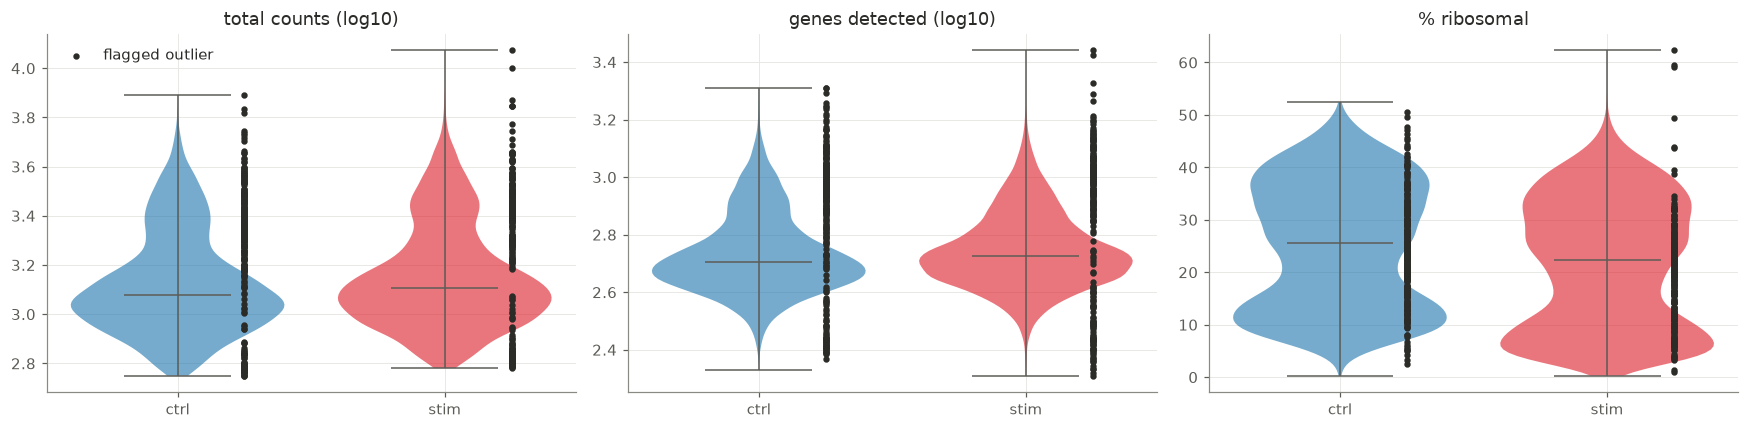

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (metric, label) in zip(axes, [("n_counts", "total counts (log10)"), ("n_genes", "genes detected (log10)"), ("pct_ribo", "% ribosomal")]):
    for k, c in enumerate(["ctrl", "stim"]):
        vals = obs.loc[obs.condition == c, metric]
        vals = np.log10(vals) if metric != "pct_ribo" else vals
        part = ax.violinplot(vals, positions=[k], widths=0.8, showmedians=True)
        neutral_lines(part)
        part["bodies"][0].set_facecolor(COND_COLORS[c]); part["bodies"][0].set_alpha(0.6)
        out = obs.loc[(obs.condition == c) & obs.flag_outlier, metric]
        ax.scatter(np.full(len(out), k) + 0.25, np.log10(out) if metric != "pct_ribo" else out, s=10, color="#2b2b28", label="flagged outlier" if k == 0 else None)
    ax.set_xticks([0, 1], ["ctrl", "stim"]); ax.set_title(label)
axes[0].legend(frameon=False)
fig.tight_layout()
display(obs.groupby("condition", observed=True)[["n_counts", "n_genes", "pct_ribo"]].median().round(1))
display(obs.groupby(["donor", "condition"], observed=True)["flag_outlier"].sum().unstack().rename(columns=lambda c: f"outliers_{c}"))
med = obs.groupby(["donor", "condition", "cell_type"], observed=True)["n_counts"].transform("median")
flagged = obs[obs.flag_outlier]
outlier_summary = pd.DataFrame({
    "flagged": flagged.groupby("cell_type", observed=True).size(),
    "cells": obs.groupby("cell_type", observed=True).size(),
}).reindex(CELL_TYPES).fillna(0).astype(int).assign(pct=lambda d: (100 * d.flagged / d.cells).round(1))
print(f"flagged {len(flagged)}: {int((flagged.n_counts > med[flagged.index]).sum())} above their group's median counts, "
      f"{int((flagged.n_counts <= med[flagged.index]).sum())} at or below")
display(outlier_summary)

### Outliers within each donor × condition × cell type group (how they are actually computed)
One panel per cell type; one column per donor × condition. Each column shows its group's **median** (solid) and **± 5 MAD cutoffs** (dashed).
A cell is flagged if it's outside the cutoffs on log counts (first figure) **or** log genes (second figure).
**Filled dark** = flagged on the metric shown (outside the dashed lines). **Hollow** = flagged only on the *other* metric, so it can sit inside the lines.
Groups with < 10 cells are not assessed (grey, no cutoffs).

flagged on counts only: 92 | genes only: 201 | both: 221


donor             patient_101      patient_107      patient_1015      patient_1016      patient_1039      patient_1244      patient_1256      patient_1488     
condition                ctrl stim        ctrl stim         ctrl stim         ctrl stim         ctrl stim         ctrl stim         ctrl stim         ctrl stim
cell_type                                                                                                                                                      
B cells                     5    2           0    2           20   12            6    3            0    2            2    1            5    5            9   11
CD14+ Monocytes             2    1           2    1            1    1            0    0            0    0            0    2            1    3            0    0
CD4 T cells                 2    7           3    5           20   21            4    1            4    3           26    8           15    9           23   21
CD8 T cells                 2    3      

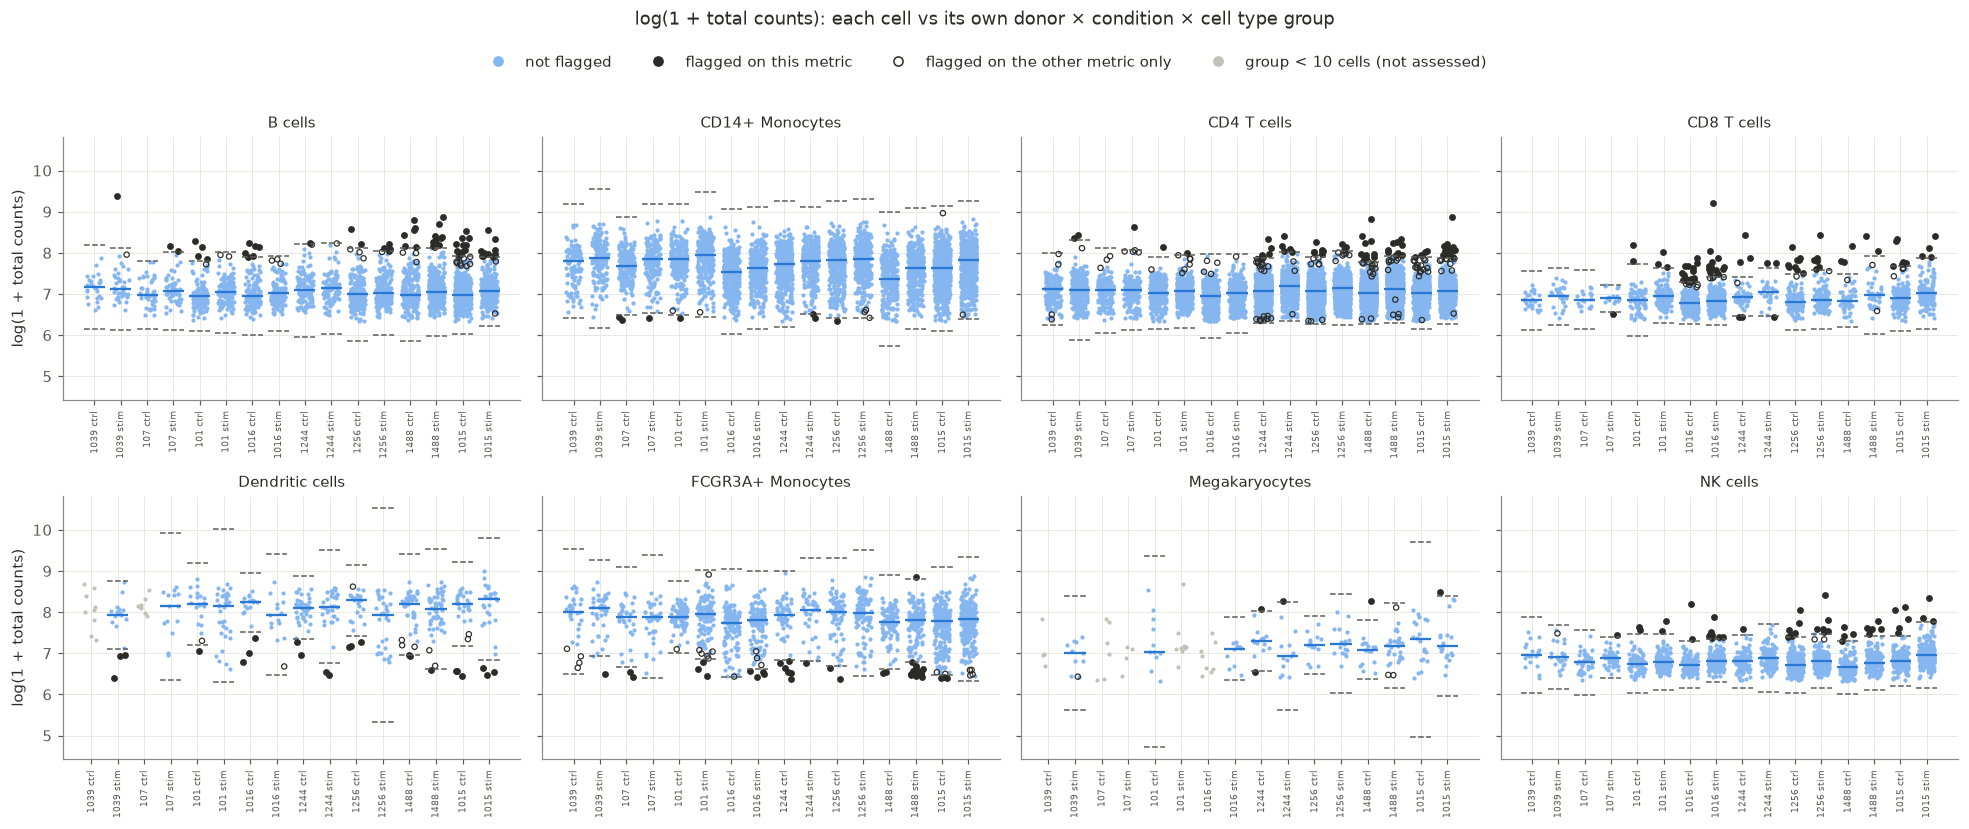

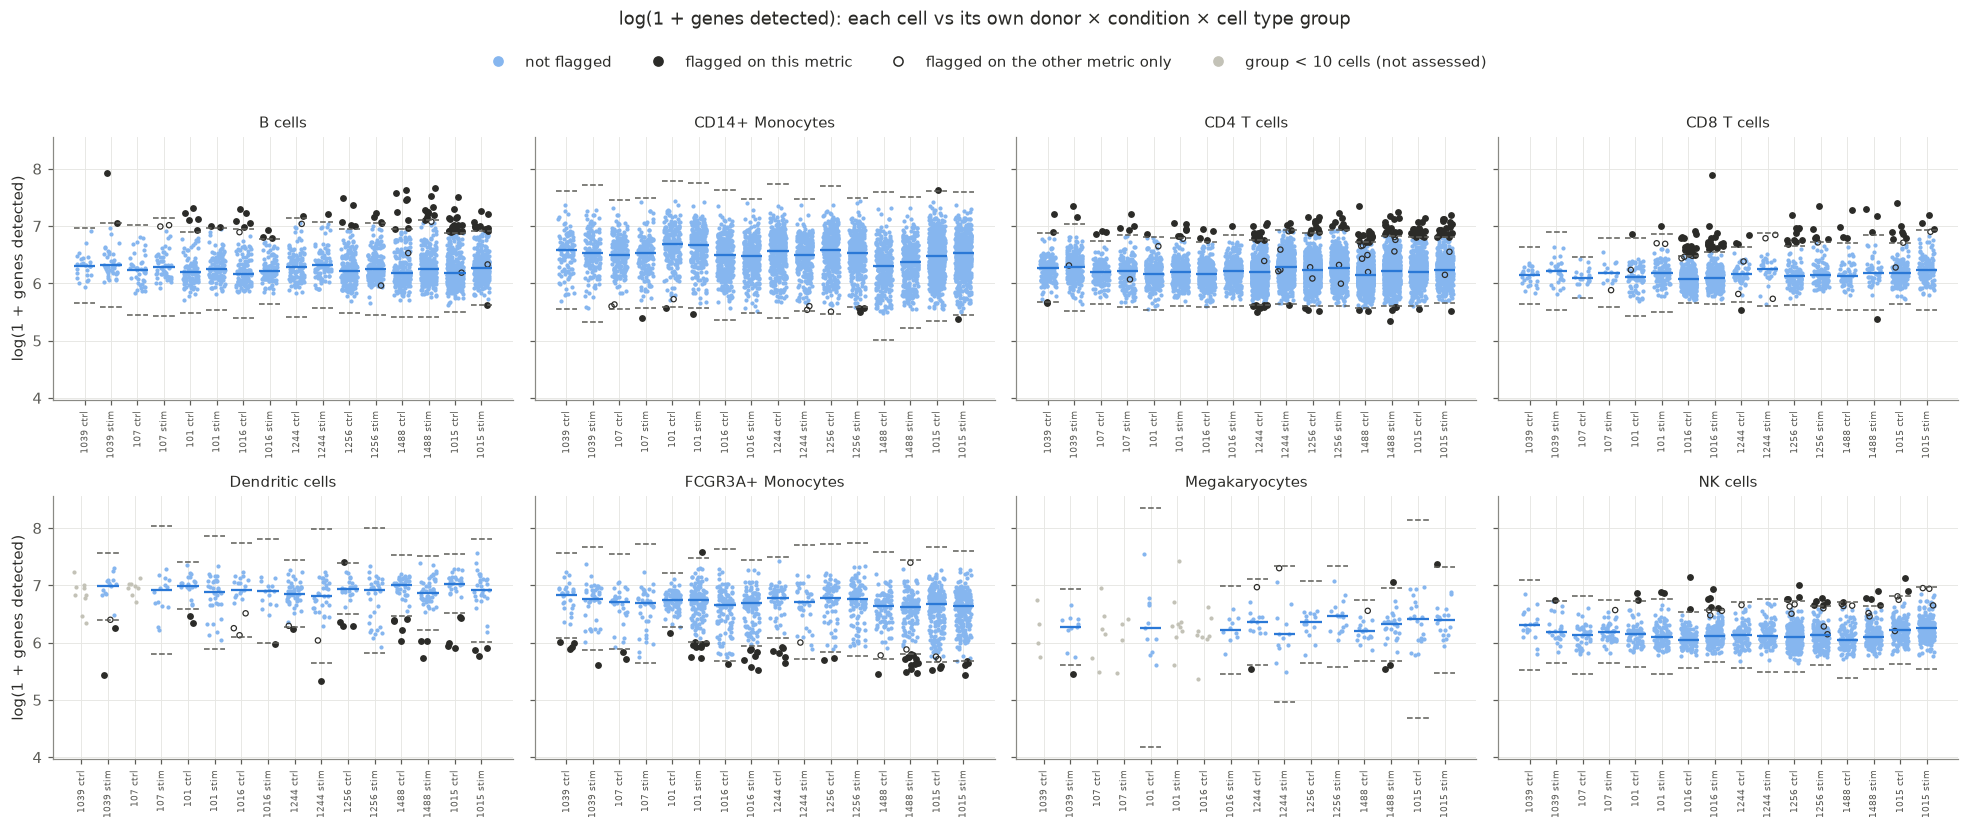

In [13]:
# Per-metric flags, recomputed with the pipeline's own function; their union must equal the pipeline's flag_outlier.
per_metric = {m: pd.Series(False, index=obs.index) for m in ("n_counts", "n_genes")}
for _, g in obs.groupby(["donor", "condition", "cell_type"], observed=True):
    if len(g) >= MIN_CELLS_GROUP:
        for m in per_metric:
            per_metric[m].loc[g.index] = m0_qc.mad_outlier(np.log1p(g[m].to_numpy(float)), N_MADS)
assert ((per_metric["n_counts"] | per_metric["n_genes"]) == obs["flag_outlier"]).all(), "per-metric flags don't reproduce flag_outlier"
print("flagged on counts only:", int((per_metric["n_counts"] & ~per_metric["n_genes"]).sum()),
      "| genes only:", int((per_metric["n_genes"] & ~per_metric["n_counts"]).sum()),
      "| both:", int((per_metric["n_counts"] & per_metric["n_genes"]).sum()))


def plot_group_outliers(metric, label):
    other = "n_genes" if metric == "n_counts" else "n_counts"
    fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
    rng = np.random.default_rng(0)
    cols = [(d, c) for d in donors for c in ["ctrl", "stim"]]
    for ax, ct in zip(axes.ravel(), CELL_TYPES):
        for x, (d, c) in enumerate(cols):
            g = obs[(obs.cell_type == ct) & (obs.donor == d) & (obs.condition == c)]
            if g.empty:
                continue
            v = np.log1p(g[metric].to_numpy(float))
            jx = x + rng.uniform(-0.3, 0.3, len(v))
            this = per_metric[metric].loc[g.index].to_numpy()
            only_other = per_metric[other].loc[g.index].to_numpy() & ~this
            normal = ~this & ~only_other
            assessed = len(g) >= MIN_CELLS_GROUP
            ax.scatter(jx[normal], v[normal], s=3, color="#86b6ef" if assessed else "#c3c2b7", rasterized=True)
            ax.scatter(jx[only_other], v[only_other], s=12, facecolors="none", edgecolors="#2b2b28", linewidths=0.8)
            ax.scatter(jx[this], v[this], s=12, color="#2b2b28")
            if assessed:
                med = np.median(v); mad = np.median(np.abs(v - med))
                ax.hlines(med, x - 0.4, x + 0.4, color="#2a78d6", lw=1.5)
                ax.hlines([med - N_MADS * mad, med + N_MADS * mad], x - 0.4, x + 0.4, color="#5c5c57", lw=1, ls="--")
        ax.set_title(ct, fontsize=10)
        ax.set_xticks(range(len(cols)), [f"{d.replace('patient_', '')} {c}" for d, c in cols], rotation=90, fontsize=6)
    for ax in axes[:, 0]:
        ax.set_ylabel(label)
    handles = [plt.Line2D([], [], marker="o", ls="", color="#86b6ef", label="not flagged"),
               plt.Line2D([], [], marker="o", ls="", color="#2b2b28", label="flagged on this metric"),
               plt.Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="#2b2b28", label="flagged on the other metric only"),
               plt.Line2D([], [], marker="o", ls="", color="#c3c2b7", label="group < 10 cells (not assessed)")]
    fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.03))
    fig.suptitle(f"{label}: each cell vs its own donor × condition × cell type group", y=1.07)
    fig.tight_layout()

plot_group_outliers("n_counts", "log(1 + total counts)")
plot_group_outliers("n_genes", "log(1 + genes detected)")
print(obs.groupby(["cell_type", "donor", "condition"], observed=True)["flag_outlier"].sum()
      .unstack(["donor", "condition"]).reindex(CELL_TYPES).fillna(0).astype(int).to_string())

## 8. Design checks: donor × condition × cell type counts
Groups with < 10 cells are too small for a reliable pseudobulk sample (flagged). This table is the input for decision **D3**.

In [14]:
table = obs.groupby(["cell_type", "donor", "condition"], observed=True).size().unstack(["donor", "condition"]).reindex(CELL_TYPES).fillna(0).astype(int)
display(table.style.apply(lambda s: ["background-color: #fde2e1" if x < 10 else "" for x in s], axis=1))
pairs = pd.DataFrame({ct: {"donors with both conditions ≥ 10 cells": int(((table.loc[ct].unstack() >= 10).all(axis=1)).sum()),
                           "flag_underpowered_celltype": bool(obs.loc[obs.cell_type == ct, "flag_underpowered_celltype"].iloc[0])}
                      for ct in CELL_TYPES}).T
display(pairs)

,donors with both conditions ≥ 10 cells,flag_underpowered_celltype
B cells,8,False
CD14+ Monocytes,8,False
CD4 T cells,8,False
CD8 T cells,8,False
Dendritic cells,6,False
FCGR3A+ Monocytes,8,False
Megakaryocytes,4,False
NK cells,8,False


## 9. Weak donors, composition shifts (Kang Fig 3d), covariate trends: numbers and plots, no automatic flags

,cells,fraction of median donor
donor,,
patient_101,2024,0.60
patient_107,1042,0.31
patient_1015,5090,1.52
patient_1016,3358,1.00
patient_1039,992,0.30
patient_1244,3343,1.00
patient_1256,4134,1.23
patient_1488,4579,1.37


Proportion stim − ctrl, per donor (percentage points)


cell_type,B cells,CD14+ Monocytes,CD4 T cells,CD8 T cells,Dendritic cells,FCGR3A+ Monocytes,Megakaryocytes,NK cells
donor,,,,,,,,
patient_1039,0.3,-1.8,2.0,-1.4,0.7,-0.2,0.9,-0.5
patient_107,1.8,-8.2,4.9,-1.0,1.1,0.9,-0.4,1.0
patient_101,-0.9,-1.8,-1.4,0.4,0.5,3.0,-0.5,0.8
patient_1016,-0.2,-1.3,-2.9,-1.2,-0.2,1.2,0.1,4.5
patient_1244,0.2,-2.3,1.5,-0.9,-0.2,-0.6,0.1,2.2
patient_1256,0.0,0.0,-0.4,-0.7,0.3,1.5,0.2,-1.0
patient_1488,0.2,-0.8,-0.0,-1.2,0.0,0.7,0.3,0.9
patient_1015,-2.0,0.1,0.2,-0.9,0.2,0.5,0.1,1.8


Median stim / ctrl ratio of each technical covariate, per cell type


,n_counts,n_genes,pct_ribo
cell_type,,,
B cells,1.06,1.07,0.84
CD14+ Monocytes,1.13,1.00,0.53
CD4 T cells,1.07,1.05,0.91
CD8 T cells,1.07,1.03,0.85
Dendritic cells,0.90,0.93,0.69
FCGR3A+ Monocytes,1.06,0.98,0.72
Megakaryocytes,0.97,1.06,1.03
NK cells,1.09,1.02,0.79


Median covariates per donor × condition


n_counts  n_genes   pct_ribo
donor        condition                              
patient_101  ctrl         1239.5    534.0  21.400000
             stim         1311.0    546.0  18.299999
patient_107  ctrl         1465.0    542.0  15.200000
             stim         1390.0    541.0  14.500000
patient_1015 ctrl         1244.0    528.0  21.000000
             stim         1349.5    551.0  17.100000
patient_1016 ctrl         1015.0    469.0  23.299999
             stim         1084.0    491.0  19.100000
patient_1039 ctrl         1377.0    564.0  23.299999
             stim         1426.5    567.0  16.200001
patient_1244 ctrl         1276.0    512.0  31.900000
             stim         1369.0    550.5  28.400000
patient_1256 ctrl         1189.0    517.0  26.700001
             stim         1271.5    534.0  23.000000
patient_1488 ctrl         1162.5    478.0  33.599998
             stim         1261.0    512.0  30.200001

Each donor's median / overall median


,n_counts,n_genes,pct_ribo
donor,,,
patient_101,1.03,1.04,0.84
patient_107,1.14,1.04,0.63
patient_1015,1.04,1.04,0.80
patient_1016,0.85,0.92,0.89
patient_1039,1.13,1.09,0.81
patient_1244,1.06,1.01,1.26
patient_1256,0.99,1.01,1.04
patient_1488,0.98,0.95,1.32


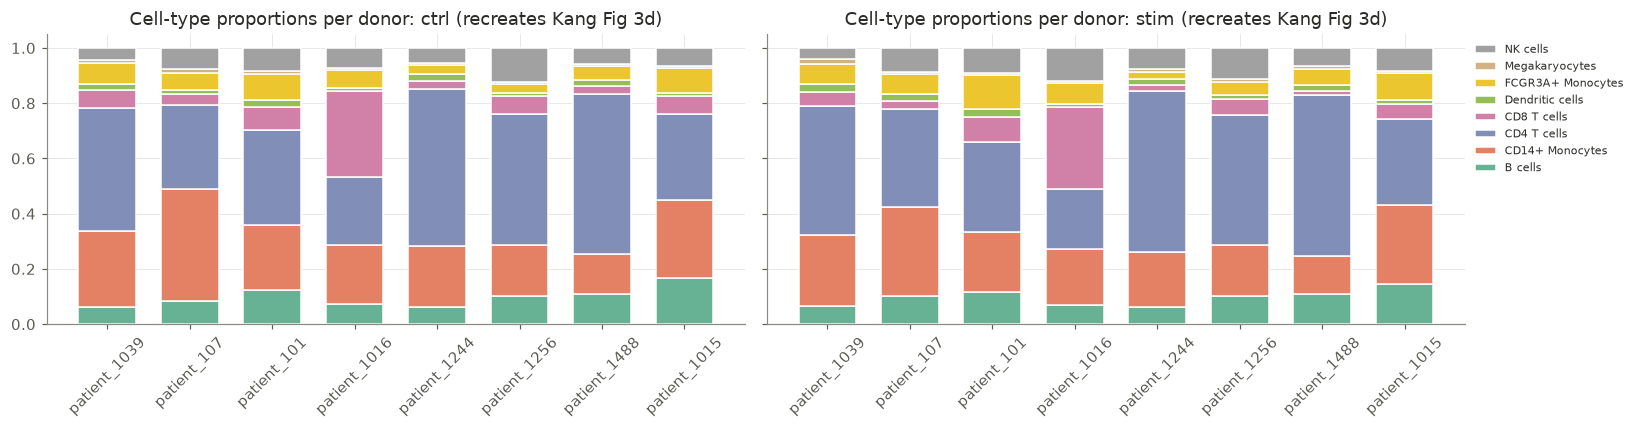

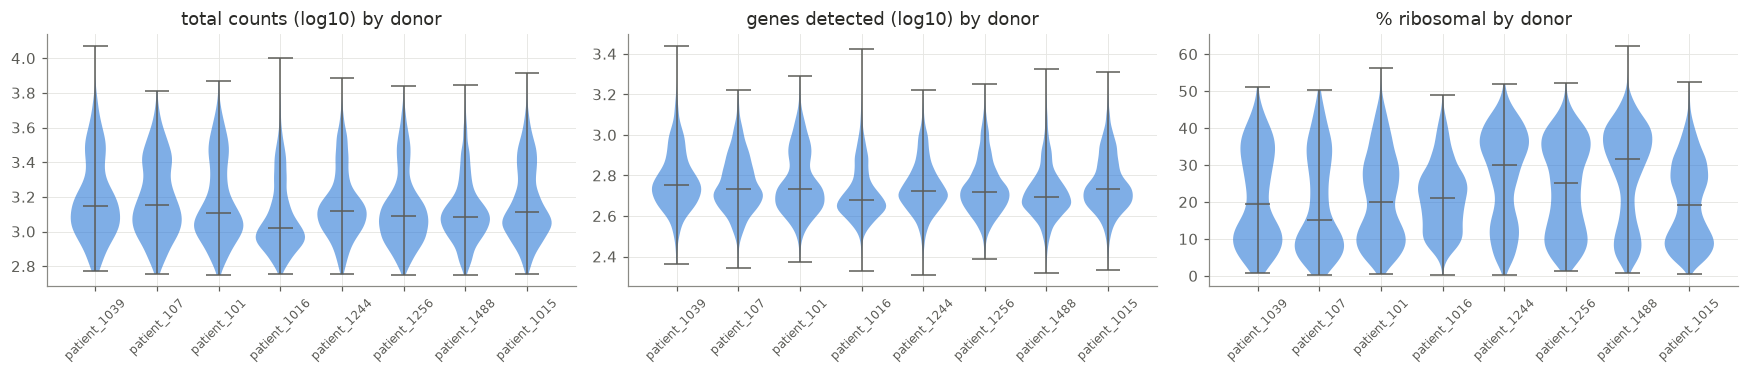

In [15]:
tot = obs.groupby("donor", observed=True).size()
display(pd.DataFrame({"cells": tot, "fraction of median donor": (tot / tot.median()).round(2)}))

prop = (obs.groupby(["donor", "condition", "cell_type"], observed=True).size()
        .groupby(level=["donor", "condition"], observed=True).transform(lambda s: s / s.sum()).unstack("cell_type")[CELL_TYPES])
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, ["ctrl", "stim"]):
    p = prop.xs(c, level="condition").loc[donors]
    bottom = np.zeros(len(donors))
    for ct in STACK_ORDER:
        ax.bar(donors, p[ct], bottom=bottom, color=CT_COLORS[ct], label=ct, width=0.7, edgecolor="white", linewidth=1)
        bottom += p[ct].values
    ax.set_title(f"Cell-type proportions per donor: {c} (recreates Kang Fig 3d)"); ax.tick_params(axis="x", rotation=45)
h, l = axes[1].get_legend_handles_labels(); axes[1].legend(h[::-1], l[::-1], frameon=False, fontsize=7, bbox_to_anchor=(1, 1))
fig.tight_layout()
shift = (prop.xs("stim", level="condition") - prop.xs("ctrl", level="condition")).loc[donors]
print("Proportion stim − ctrl, per donor (percentage points)"); display((100 * shift).round(1))

cov = obs.groupby(["cell_type", "condition"], observed=True)[["n_counts", "n_genes", "pct_ribo"]].median().unstack("condition")
ratio = pd.DataFrame({m: (cov[(m, "stim")] / cov[(m, "ctrl")]).round(2) for m in ["n_counts", "n_genes", "pct_ribo"]})
print("Median stim / ctrl ratio of each technical covariate, per cell type"); display(ratio.reindex(CELL_TYPES))

# Covariates by donor (D5): medians per donor × condition, and each donor's median relative to all donors
by_donor = obs.groupby(["donor", "condition"], observed=True)[["n_counts", "n_genes", "pct_ribo"]].median().round(1)
rel_donor = (obs.groupby("donor", observed=True)[["n_counts", "n_genes", "pct_ribo"]].median()
             / obs[["n_counts", "n_genes", "pct_ribo"]].median()).round(2)
print("Median covariates per donor × condition"); display(by_donor)
print("Each donor's median / overall median"); display(rel_donor)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, (metric, label) in zip(axes, [("n_counts", "total counts (log10)"), ("n_genes", "genes detected (log10)"), ("pct_ribo", "% ribosomal")]):
    for i, d in enumerate(donors):
        vals = obs.loc[obs.donor == d, metric]
        part = ax.violinplot(np.log10(vals) if metric != "pct_ribo" else vals, positions=[i], widths=0.8, showmedians=True)
        neutral_lines(part); part["bodies"][0].set_facecolor("#2a78d6"); part["bodies"][0].set_alpha(0.6)
    ax.set_xticks(range(len(donors)), donors, rotation=45, fontsize=8); ax.set_title(f"{label} by donor")
fig.tight_layout()

## 10. Reading the data correctly: authors' t-SNE (recreates Kang Fig 3a)

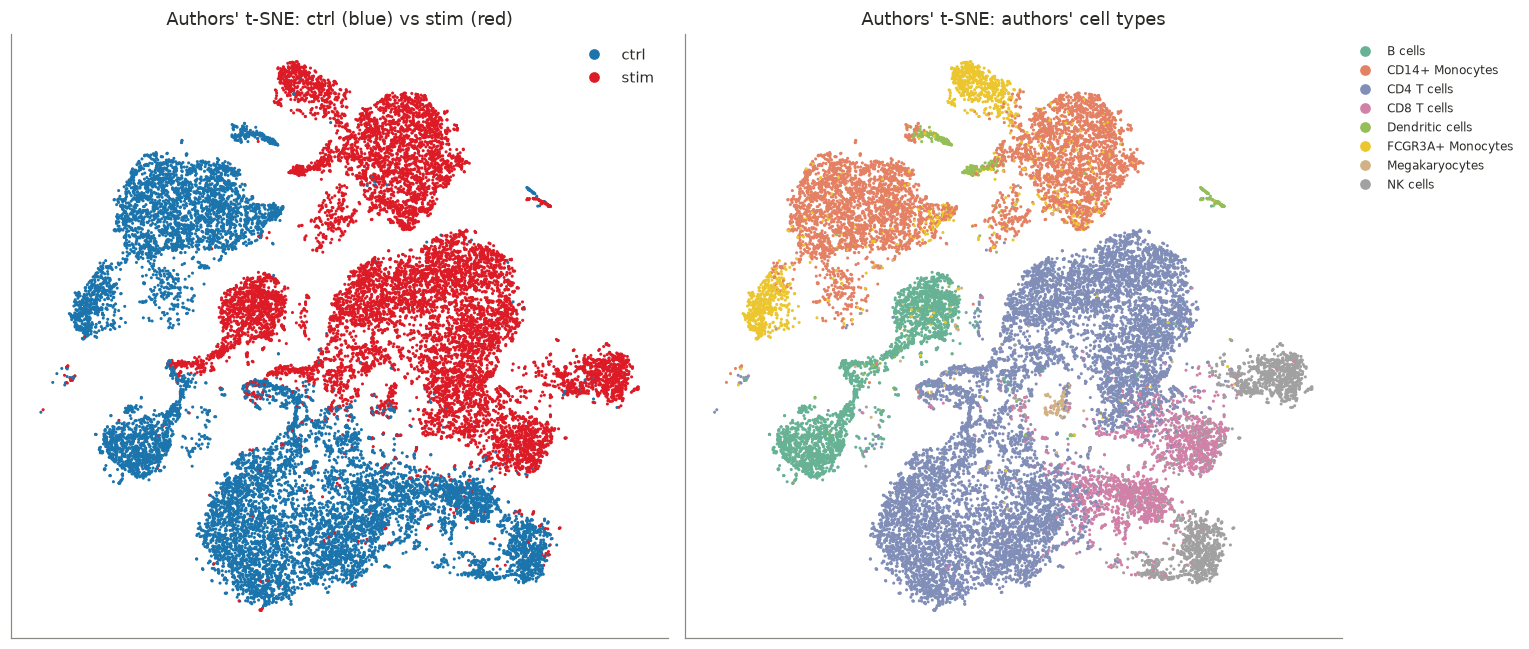

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order = np.random.default_rng(0).permutation(len(obs))  # random draw order so neither condition hides the other
o = obs.iloc[order]
axes[0].scatter(o.tsne1, o.tsne2, s=1, c=o.condition.map(COND_COLORS).values, rasterized=True)
axes[0].set_title("Authors' t-SNE: ctrl (blue) vs stim (red)")
axes[1].scatter(o.tsne1, o.tsne2, s=1, c=o.cell_type.map(CT_COLORS).values, rasterized=True)
axes[1].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=CT_COLORS[ct], label=ct) for ct in CELL_TYPES],
               frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COND_COLORS[c], label=c) for c in COND_COLORS], frameon=False)
axes[1].set_title("Authors' t-SNE: authors' cell types")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.tight_layout()

## 11. Write `audit/data_facts.md` and the numbers for `audit/qc_flags.md`

In [17]:
def md(df):
    return df.to_markdown()

facts = f"""# Data facts (written by notebooks/00_eda.ipynb)

Read this instead of guessing. Source files and fingerprints are in `CLAUDE.md`.

- h5ad: {raw.n_obs} cells × {raw.n_vars} genes; `X` raw integer counts (sparse, float32 storage); no `.raw`, no layers.
- Gene names: symbols in `var_names`, unique. **No `MT-` genes** (so no % mito). {int(raw.var_names.str.match(r"^RP[SL]").sum())} genes with the RPS/RPL prefix; {int(m0_qc.ribosomal_mask(raw.var_names).sum())} counted as ribosomal after excluding 14 non-ribosomal genes (decision D4).
- Key ISGs present: {", ".join(g for g in KEY_GENES if g in raw.var_names)}. Missing: {", ".join(g for g in KEY_GENES if g not in raw.var_names) or "none"}.
- Conditions: `ctrl` (control) / `stim` (treatment); stored as `uns['control']` / `uns['treatment']` in the M0 output.
- Donors: {", ".join(donors)} (column `donor`, from h5ad `replicate`); GEO `ind` holds the bare number.
- Cell types (authors', GEO `cell`): {", ".join(CELL_TYPES)}.
- Join: key (barcode without suffix, condition); {joined.n_obs}/{raw.n_obs} matched; {n_both} sequences occur in both conditions among these singlets (313 across all GEO droplets).
- The h5ad's own `cell_type` (re-analysis) agrees with the authors' on {agree:.1%} of cells; not used.
- Basic filters: cells {qc.n_obs} → {filtered.n_obs}; genes {qc.n_vars} → {filtered.n_vars}.
- M0 output: `data/processed/m0_cells.h5ad`, {m0.n_obs} cells × {m0.n_vars} genes.

## Cells per donor × condition

{md(by_cond.assign(total=by_cond.sum(1)))}

## Cells per cell type × donor × condition

{md(table)}
"""
(ROOT / "audit/data_facts.md").write_text(facts)

small = obs[obs.flag_small_group].groupby(["cell_type", "donor", "condition"], observed=True).size()
flag_numbers = f"""# QC flag numbers (written by notebooks/00_eda.ipynb; proposed actions are added at review)

## Outlier cells (> 5 raw MADs above or below, on log counts or log genes, within donor × condition × cell type; groups < 10 cells not assessed)

{md(obs.groupby(["donor", "condition"], observed=True)["flag_outlier"].sum().unstack())}

By cell type:

{md(outlier_summary)}

## Groups with < 10 cells (donor × condition × cell type)

{md(small.to_frame("cells")) if len(small) else "none"}

## Cell types by donors with both conditions ≥ 10 cells

{md(pairs)}

## Donor sizes

{md(pd.DataFrame({"cells": tot, "fraction of median donor": (tot / tot.median()).round(2)}))}

## Composition shift, stim − ctrl (percentage points)

{md((100 * shift).round(1))}

## Technical covariates: median stim / ctrl ratio per cell type

{md(ratio.reindex(CELL_TYPES))}

## Technical covariates by donor: each donor's median / overall median

{md(rel_donor)}
"""
(ROOT / "audit/qc_flag_numbers.md").write_text(flag_numbers)
print("wrote audit/data_facts.md, audit/qc_flag_numbers.md, audit/cell_flow.md")

wrote audit/data_facts.md, audit/qc_flag_numbers.md, audit/cell_flow.md
